# Etapa II · Fase 2 · Bloque C-5: SVD

**Pregunta:** ¿ayuda reducir la dimensionalidad con `TruncatedSVD` antes del clasificador?

| | |
|---|---|
| **Factor que cambia** | `n_components`: sin SVD, 50, 100, 200 |
| **Fijo** | La normalización y la representación de la mejor configuración de cada modelo |
| **Modelos** | LogisticRegression y SVC; MultinomialNB se excluye porque el SVD produce valores negativos |
| **Experimentos** | C22--C29 |

In [1]:
%matplotlib inline

In [2]:
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig")
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)
print("Raíz:", ROOT)


Raíz: /home/mrangello/Documentos/PracticaML


In [3]:
exp = pd.read_csv(ROOT / "results/etapa2/experiments.tsv", sep="\t",
                   dtype=str, keep_default_na=False)

def dev_macro_f1(row):
    return float(row["dev_metric"].split("macro_f1=")[1].split(";")[0])

def extra_dict(row):
    return dict(part.split("=", 1) for part in row["extra"].split("; "))

def get(exp_id):
    return exp[exp["experiment_id"] == exp_id].iloc[0]


## 1. C-5 original y complemento

C22--C25 prueban SVD sobre la mejor configuración de C-4: para LR, bigramas (C18); para
SVC, unigramas (C06). Después se añadió un complemento, C26--C29, para probar SVD sobre la
**configuración final** de LR (C02, unigramas) y completar la curva de SVC con 50
componentes.

In [4]:
rows = [
    ("LogisticRegression", "sin SVD", "C02"),
    ("LogisticRegression", "SVD 50", "C28"),
    ("LogisticRegression", "SVD 100", "C26"),
    ("LogisticRegression", "SVD 200", "C27"),
    ("SVC", "sin SVD", "C06"),
    ("SVC", "SVD 50", "C29"),
    ("SVC", "SVD 100", "C24"),
    ("SVC", "SVD 200", "C25"),
]
table = pd.DataFrame([{
    "Modelo": model,
    "Configuración": config,
    "Exp.": exp_id,
    "Dev macro-F1": round(dev_macro_f1(get(exp_id)), 4),
    "CV macro-F1": round(float(get(exp_id)["cv_macro_f1"]), 4),
    "n_features": int(extra_dict(get(exp_id))["n_features"]),
} for model, config, exp_id in rows])
display(table)

,Modelo,Configuración,Exp.,Dev macro-F1,CV macro-F1,n_features
0,LogisticRegression,sin SVD,C02,0.7993,0.7675,6689
1,LogisticRegression,SVD 50,C28,0.7706,0.7411,3033
2,LogisticRegression,SVD 100,C26,0.7586,0.7601,3033
3,LogisticRegression,SVD 200,C27,0.7475,0.7653,3033
4,SVC,sin SVD,C06,0.7742,0.7451,9974
5,SVC,SVD 50,C29,0.7880,0.7040,4608
6,SVC,SVD 100,C24,0.7504,0.7319,9974
7,SVC,SVD 200,C25,0.7751,0.7302,9974


**Nota sobre hiperparámetros:** en cada experimento se reajustan `C` y `min_df`
con la misma rejilla que en el resto de bloques. Por eso las filas de LR con SVD usan
`min_df=2` (3 033 rasgos) y C02 usa `min_df=1` (6 689); en SVC, C29 usa `min_df=2` (4 608)
y C06 `min_df=1` (9 974). No es una comparación con hiperparámetros fijos: es la mejor
versión de cada configuración, igual que en C-3 y C-4.

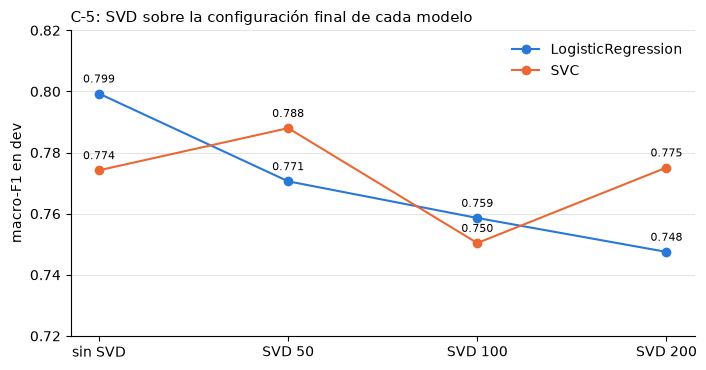

In [5]:
order = ["sin SVD", "SVD 50", "SVD 100", "SVD 200"]
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for model, color in [("LogisticRegression", "#2a78d6"), ("SVC", "#eb6834")]:
    sub = table[table["Modelo"] == model].set_index("Configuración").loc[order]
    ax.plot(order, sub["Dev macro-F1"], marker="o", color=color, label=model)
    for x, y in zip(order, sub["Dev macro-F1"]):
        ax.annotate(f"{y:.3f}", (x, y), textcoords="offset points",
                    xytext=(0, 8), ha="center", fontsize=8)
ax.set_ylim(0.72, 0.82)
ax.set_ylabel("macro-F1 en dev")
ax.set_title("C-5: SVD sobre la configuración final de cada modelo", loc="left", fontsize=11)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e4e0", lw=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 2. El C-5 original (LR con bigramas)

C22 (SVD 100) y C23 (SVD 200) usan la configuración de C-4 para LR (bigramas C18):

In [6]:
display(exp[exp["experiment_id"].isin(["C22", "C23"])][
    ["experiment_id", "normalization", "representation", "ngram_range",
     "svd_components", "cv_macro_f1", "dev_metric"]
])

,experiment_id,normalization,representation,ngram_range,svd_components,cv_macro_f1,dev_metric
21,C22,N2,tfidf,"(1,2)",100,0.7654,macro_f1=0.7573; accuracy=0.7600
22,C23,N2,tfidf,"(1,2)",200,0.7849,macro_f1=0.7713; accuracy=0.7733


## 3. Lectura

- **LR:** el SVD no ayuda. Sobre C02 (unigramas), SVD 50 da 0.7706, SVD 100 0.7586 y SVD
  200 0.7475, todos por debajo de 0.7993 sin SVD. Sobre bigramas, C22/C23 dan 0.7573/0.7713,
  también por debajo de C18 (0.8007).
- **SVC:** SVD 50 (C29) sube a 0.7880 en dev, +1.4 puntos sobre C06 (0.7742), pero su CV es
  0.7040 frente a 0.7451. SVD 100/200 quedan en 0.7504/0.7751.
- **C29 se añadió después de congelar la selección y de evaluar test.** Por el protocolo de
  test único no se re-evaluó; se mantiene **C06** como SVC de referencia y C29 queda como
  línea para un test independiente.
- **Conclusión:** el SVD no aporta a LR. En SVC hay una mejora dev pequeña con 50
  componentes, pero con menor CV y sin validación en test; no cambia la selección.